In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import generate_behavdf as gm
# from preproc_funcs import *
# from generate_plots import *
# from helpers import *
# from preproc_funcs import *
from scipy import stats
import plotly.graph_objects as go
from statsmodels.stats.anova import AnovaRM
import pingouin as pg

pd.set_option("display.max.columns", None)
pd.set_option("display.precision", 4)

msize = 10
axes_fontsize = 14
title_fontsize = 18
%load_ext autoreload
%autoreload 2

Creating a new dataframe...
We have 1 subjects so far: [99]



In [2]:
df = gm.master_df
oriArrayCols = [col for col in df.columns if col.startswith('oriArray_')]
df['oriSteps'] = df[oriArrayCols].notna().sum(axis=1)
df['abserrorOri'] = np.abs(df['errorOri'])

In [3]:
df.head()

,subjID,day,block,TMScond,stimPF,targOriCategory,targOriActual,stimSize,targX,targY,rho,polang,initDuration,sampleDuration,delay1Duration,delay2Duration,respDuration,feedbackDuration,itiDuration,trialDuration,initOri,oriArray_1,oriArray_2,oriArray_3,oriArray_4,oriArray_5,oriArray_6,oriArray_7,oriArray_8,oriArray_9,oriArray_10,oriArray_11,oriArray_12,oriArray_13,oriArray_14,oriArray_15,oriArray_16,oriArray_17,oriArray_18,oriArray_19,oriArray_20,oriArray_21,oriArray_22,oriArray_23,oriArray_24,oriArray_25,oriArray_26,oriArray_27,oriArray_28,oriArray_29,oriArray_30,oriArray_31,oriArray_32,oriArray_33,oriArray_34,oriArray_35,oriArray_36,oriArray_37,oriArray_38,oriArray_39,oriArray_40,oriArray_41,oriArray_42,oriArray_43,oriArray_44,oriArray_45,oriArray_46,oriArray_47,oriArray_48,oriArray_49,oriArray_50,oriArray_51,oriArray_52,oriArray_53,oriArray_54,oriArray_55,oriArray_56,oriArray_57,oriArray_58,oriArray_59,oriArray_60,oriArray_61,oriArray_62,oriArray_63,oriArray_64,oriArray_65,oriArray_66,oriArray_67,oriArray_68,oriArray_69,oriArray_70,oriArray_71,oriArray_72,oriArray_73,oriArray_74,oriArray_75,oriArray_76,oriArray_77,oriArray_78,oriArray_79,oriArray_80,oriArray_81,oriArray_82,oriArray_83,oriArray_84,oriArray_85,oriArray_86,oriArray_87,oriArray_88,oriArray_89,oriArray_90,oriArray_91,oriArray_92,oriArray_93,oriArray_94,oriArray_95,oriArray_96,oriArray_97,oriArray_98,oriArray_99,oriArray_100,oriArray_101,oriArray_102,oriArray_103,oriArray_104,oriArray_105,oriArray_106,oriArray_107,oriArray_108,oriArray_109,oriArray_110,oriArray_111,oriArray_112,oriArray_113,oriArray_114,oriArray_115,finalOri,RT,errorOri,oriSteps,abserrorOri
0,99,3,1,1,0,120,122.8781,146,1281.0811,764.3322,391.6861,34.9411,1.0003,0.2502,4.0003,0.1670,2.4192,1.0002,1.5006,9.3389,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,30.8136,31.8136,31.8136,31.8136,29.8136,27.8136,24.8136,21.8136,18.8136,16.8136,13.8136,11.8136,7.8136,7.8136,7.8136,5.8136,3.8136,2.8136,0.8136,176.8136,172.8136,170.8136,167.8136,165.8136,162.8136,158.8136,153.8136,149.8136,145.8136,142.8136,139.8136,136.8136,133.8136,131.8136,130.8136,130.8136,130.8136,130.8136,130.8136,130.8136,130.8136,130.8136,130.8136,130.8136,131.8136,133.8136,136.8136,139.8136,141.8136,141.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,142.8136,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,142.8136,2.3518,-19.9355,87,19.9355
1,99,3,1,1,0,120,120.6060,146,1281.0811,764.3322,391.6861,34.9411,1.0003,0.2502,4.0003,0.1464,1.8741,1.0002,1.5002,8.7727,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,125.0692,126.0692,127.0692,127.0692,128.0692,128.0692,128.0692,128.0692,129.0692,130.0692,133.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,134.0692,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,134.0692,1.8486,-13.4631,69,13.4631
2,99,3,1,1,0,60,50.8390,146,1281.0811,764.3322,391.6861,34.9411,1.0002,0.2502,4.0003,0.1528,2.1784,1.0002,2.5002,10.0832,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,143.1360,142.1360,140.1360,138.1360,135.1360,133.1360,130.1360,127.

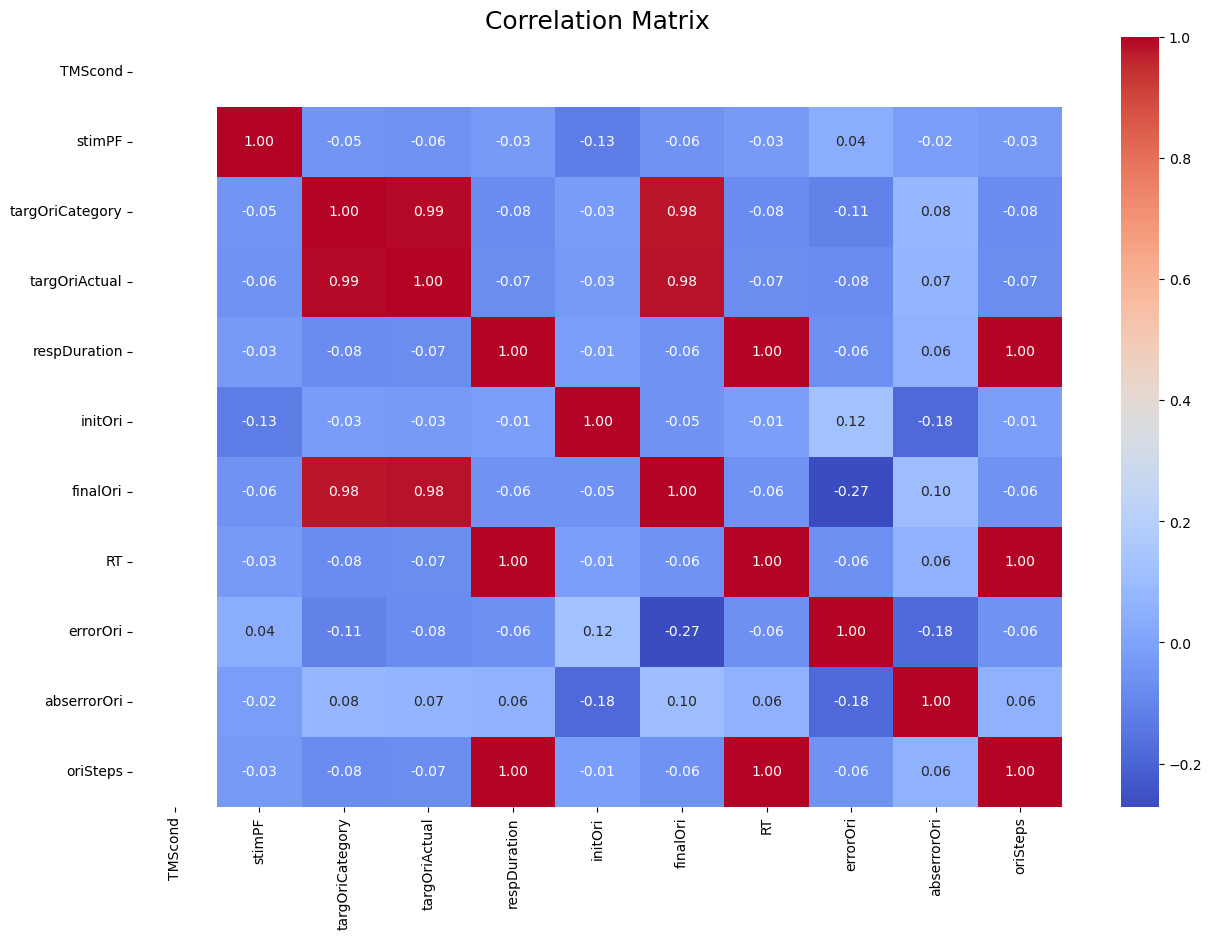

In [4]:
exploratory_cols = ['TMScond', 'stimPF', 'targOriCategory', 'targOriActual', 'respDuration', 'initOri', 'finalOri', 'RT', 'errorOri', 'abserrorOri', 'oriSteps']
plt.figure(figsize=(15, 10))
sns.heatmap(df[exploratory_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix', fontsize=title_fontsize)
plt.show()

<Figure size 1500x1000 with 0 Axes>

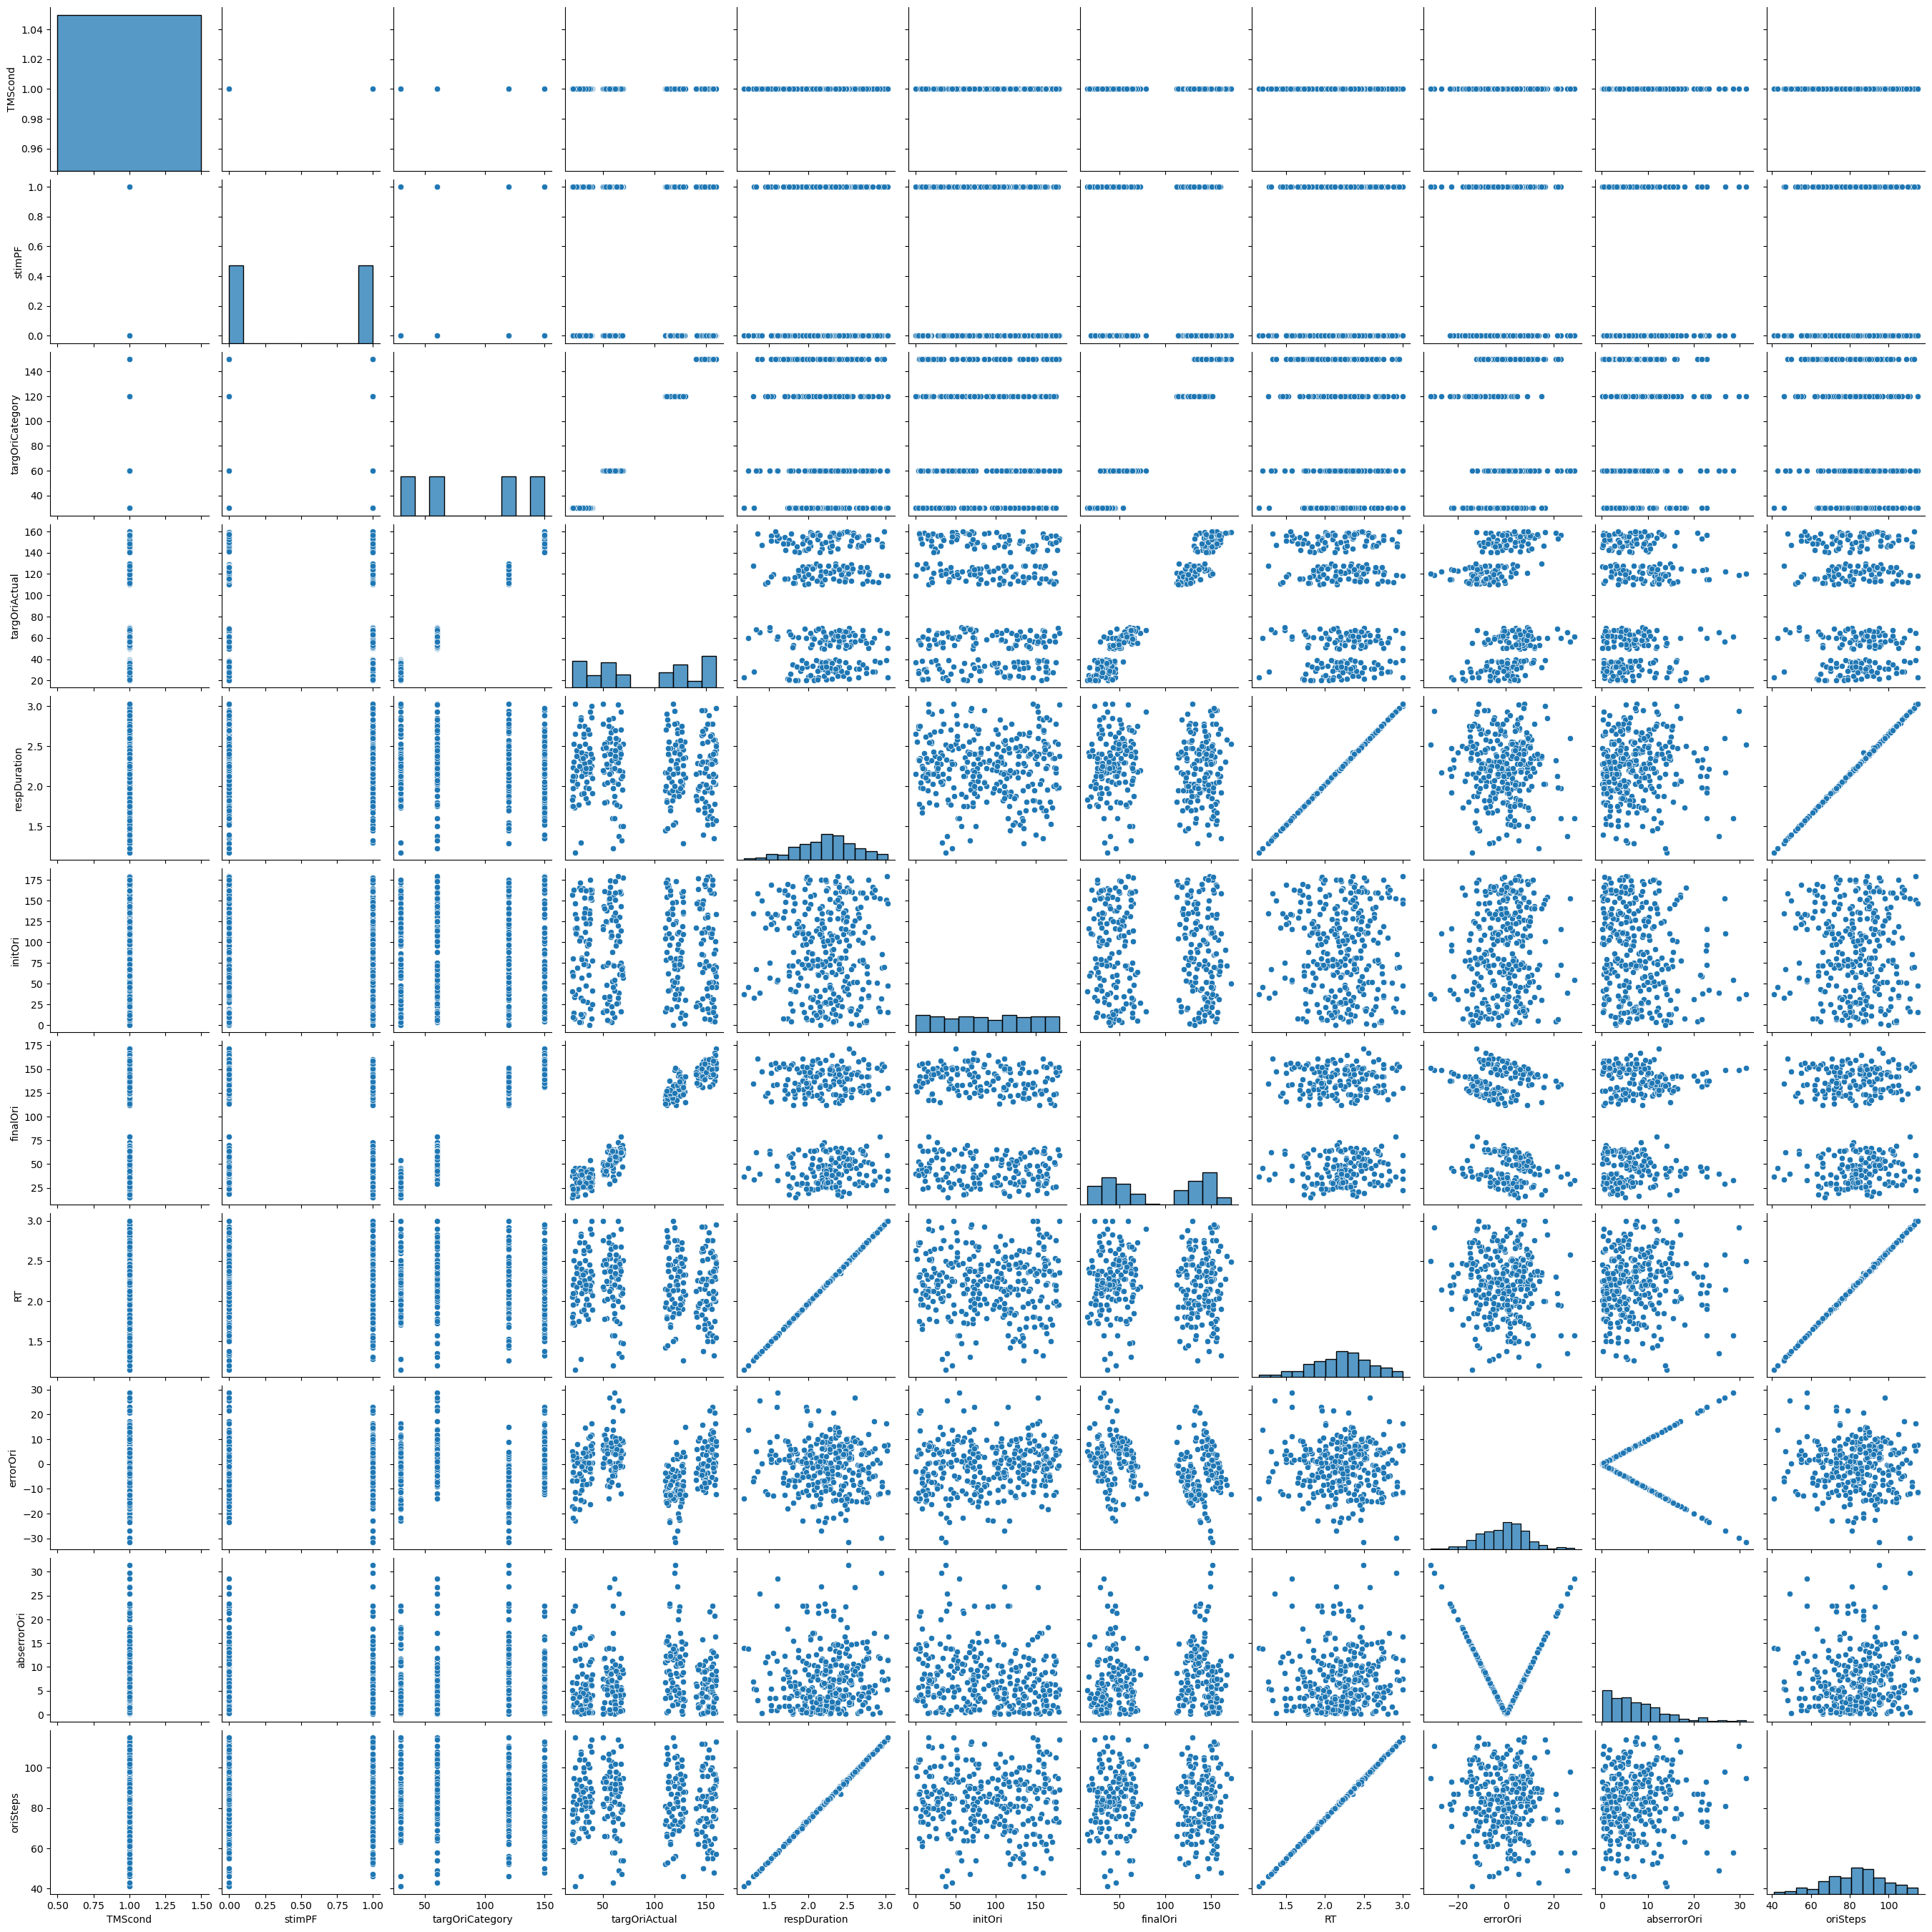

In [5]:
plt.figure(figsize=(15, 10))
sns.pairplot(df[exploratory_cols])
plt.show()

In [6]:
PF_arr = [0, 1]
targOriCategory_arr = df['targOriCategory'].unique()
RT_holder = np.empty((len(PF_arr), len(targOriCategory_arr)))
error_holder = np.empty((len(PF_arr), len(targOriCategory_arr)))

from itertools import product
for ii, jj in product(range(len(PF_arr)), range(len(targOriCategory_arr))):
    RT_holder[ii, jj] = df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'] == targOriCategory_arr[jj])]['RT'].mean()
    error_holder[ii, jj] = df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'] == targOriCategory_arr[jj])]['abserrorOri'].mean()

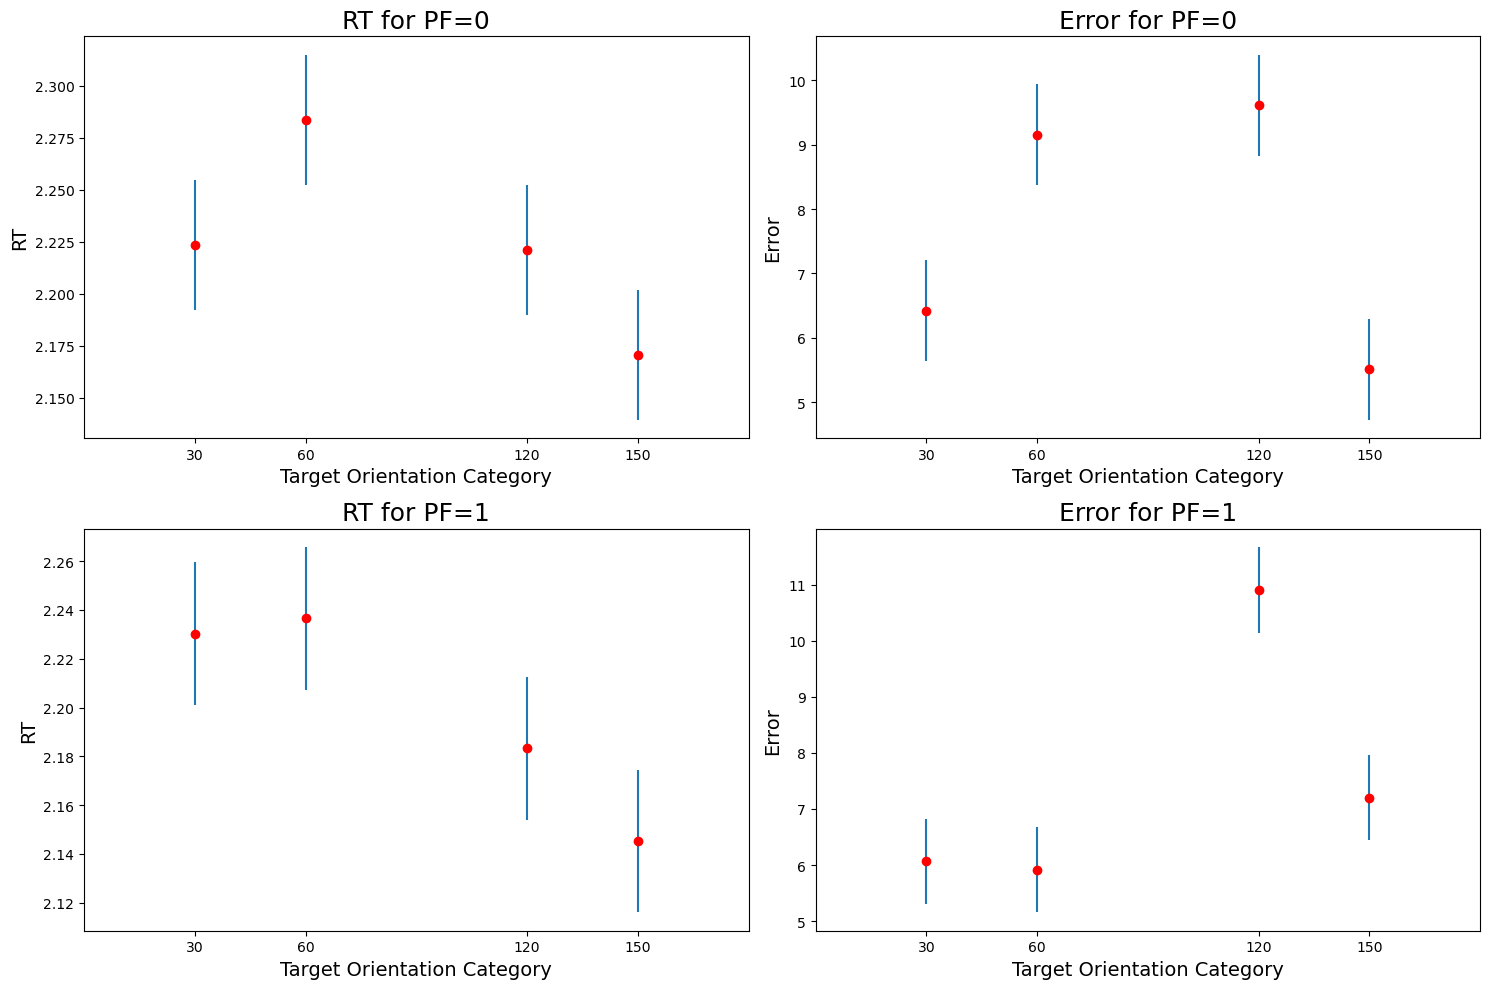

In [7]:
# Plot mean and error for both RT and error for different PF_arr
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
for ii in range(len(PF_arr)):
    # ax[ii, 0].bar(targOriCategory_arr, RT_holder[ii, :], label=f'PF={PF_arr[ii]}')
    # ax[ii, 1].bar(targOriCategory_arr, error_holder[ii, :], label=f'PF={PF_arr[ii]}')
    axs[ii, 0].errorbar(targOriCategory_arr, RT_holder[ii, :], yerr=stats.sem(df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'].isin(targOriCategory_arr))]['RT']), ls='None', label=f'PF={PF_arr[ii]}')
    axs[ii, 0].plot(targOriCategory_arr, RT_holder[ii, :], 'ro')
    axs[ii, 0].set_xlim(0, 180)
    axs[ii, 0].set_xticks(targOriCategory_arr)
    axs[ii, 0].set_title(f'RT for PF={PF_arr[ii]}', fontsize=title_fontsize)
    axs[ii, 0].set_xlabel('Target Orientation Category', fontsize=axes_fontsize)
    axs[ii, 0].set_ylabel('RT', fontsize=axes_fontsize)
    axs[ii, 1].errorbar(targOriCategory_arr, error_holder[ii, :], yerr=stats.sem(df[(df['stimPF'] == PF_arr[ii]) & (df['targOriCategory'].isin(targOriCategory_arr))]['errorOri']), ls='None', label=f'PF={PF_arr[ii]}')
    axs[ii, 1].plot(targOriCategory_arr, error_holder[ii, :], 'ro')
    axs[ii, 1].set_xlim(0, 180)
    axs[ii, 1].set_xticks(targOriCategory_arr)
    axs[ii, 1].set_title(f'Error for PF={PF_arr[ii]}', fontsize=title_fontsize)
    axs[ii, 1].set_xlabel('Target Orientation Category', fontsize=axes_fontsize)
    axs[ii, 1].set_ylabel('Error', fontsize=axes_fontsize)
plt.tight_layout()
plt.show()